# Exploratory Data Analysis: Dataset Statistics (Version 1 & Version 2)

This notebook performs comprehensive exploratory data analysis (EDA) on the TikTok harmfulness classification dataset.
Supports both **Version 1** (canonical 6,285 videos) and **Version 2** (consolidated 7,624 videos).

The analysis covers:
1. **Dataset Integrity & Label Alignment**
2. **Harm Category Distributions & Class Prevalence** (with comparative V1 vs V2 analysis)
3. **Multi-label Cardinality & Label Combinations**
4. **Pairwise Harm Co-occurrence Matrix**
5. **Video Technical Properties (OpenCV Metadata Extraction & Incremental Caching)**
6. **Video Duration Distributions**
7. **Resolution and Aspect Ratio Characteristics**
8. **Frame Rates (FPS) and File Sizes**
9. **Outlier Detection & Dataset Integrity Report**


In [12]:
from pathlib import Path
import os
import time
from concurrent.futures import ThreadPoolExecutor
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

# =============================================================================
# DATASET VERSION CONFIGURATION
# =============================================================================
# Set to 'v2' for consolidated dataset (7,624 videos) or 'v1' for canonical dataset (6,285 videos)
DATASET_VERSION = 'v2'

# External batch directory containing new videos and dataset.csv
EXTERNAL_BATCH_DIR = Path(r"D:\Workspace\KLTN\consolidated_dataset_30_10")

# Configure plot styling
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]

# Define repository paths relative to this notebook
notebook_dir = Path.cwd()
# Handle execution whether run from experiments/eda or project root
if (notebook_dir / 'data' / 'label-origin.csv').exists():
    repo_root = notebook_dir
elif (notebook_dir.parent.parent / 'data' / 'label-origin.csv').exists():
    repo_root = notebook_dir.parent.parent
else:
    repo_root = Path(r'D:/Workspace/hierachical-multimodel-multilabel')

base_csv_path = repo_root / "data" / "label-origin.csv"
video_parts_dir = repo_root / "data" / "video_parts"

# Version-specific paths
if DATASET_VERSION == 'v2':
    metadata_cache_path = repo_root / "data" / "video_metadata_v2.csv"
    outliers_report_path = repo_root / "data" / "video_outliers_report_v2.csv"
    figures_dir = repo_root / "images" / "eda" / "v2"
else:
    metadata_cache_path = repo_root / "data" / "video_metadata.csv"
    outliers_report_path = repo_root / "data" / "video_outliers_report.csv"
    figures_dir = repo_root / "images" / "eda" / "v1"

figures_dir.mkdir(parents=True, exist_ok=True)

print(f"Dataset Version : {DATASET_VERSION.upper()}")
print(f"Repo root       : {repo_root}")
print(f"Base Labels CSV : {base_csv_path} (exists: {base_csv_path.exists()})")
print(f"Video parts dir : {video_parts_dir} (exists: {video_parts_dir.exists()})")
print(f"External Batch  : {EXTERNAL_BATCH_DIR} (exists: {EXTERNAL_BATCH_DIR.exists()})")
print(f"Metadata Cache  : {metadata_cache_path}")
print(f"Figures dir     : {figures_dir}")


Dataset Version : V2
Repo root       : D:\Workspace\hierachical-multimodel-multilabel
Base Labels CSV : D:\Workspace\hierachical-multimodel-multilabel\data\label-origin.csv (exists: True)
Video parts dir : D:\Workspace\hierachical-multimodel-multilabel\data\video_parts (exists: True)
External Batch  : D:\Workspace\KLTN\consolidated_dataset_30_10 (exists: True)
Metadata Cache  : D:\Workspace\hierachical-multimodel-multilabel\data\video_metadata_v2.csv
Figures dir     : D:\Workspace\hierachical-multimodel-multilabel\images\eda\v2


## 1. Dataset Loading and Ground-Truth Integrity Check

We load `data/label-origin.csv` and verify alignment with all `.mp4` video files present across `data/video_parts/part_*`.


In [13]:
# Load canonical base labels (v1)
df_v1 = pd.read_csv(base_csv_path)
harm_cols = [c for c in df_v1.columns if c != "filename"]

# Normalize binary integer types
for col in harm_cols:
    df_v1[col] = pd.to_numeric(df_v1[col], errors="coerce").fillna(0).astype(int)
df_v1["normal_content"] = (df_v1[harm_cols].sum(axis=1) == 0).astype(int)
df_v1["is_harmful"] = (1 - df_v1["normal_content"]).astype(int)
df_v1["total_harms"] = df_v1[harm_cols].sum(axis=1)

# Scan video files from canonical video_parts/
existing_video_paths = {p.name: p for p in video_parts_dir.rglob("*.mp4")}

if DATASET_VERSION == "v2" and EXTERNAL_BATCH_DIR.exists():
    new_csv_path = EXTERNAL_BATCH_DIR / "dataset.csv"
    df_new = pd.read_csv(new_csv_path)
    for col in harm_cols:
        df_new[col] = pd.to_numeric(df_new[col], errors="coerce").fillna(0).astype(int)
    df_new["normal_content"] = (df_new[harm_cols].sum(axis=1) == 0).astype(int)
    df_new["is_harmful"] = (1 - df_new["normal_content"]).astype(int)
    df_new["total_harms"] = df_new[harm_cols].sum(axis=1)
    
    # Merge datasets without duplicate filenames
    df_labels = pd.concat([df_v1, df_new], ignore_index=True).drop_duplicates(subset=["filename"], keep="last")
    print(f"Loaded Version 2: {len(df_v1):,} (v1) + {len(df_new):,} (new) = {len(df_labels):,} total samples")
    
    # Also scan videos from external batch
    external_video_dir = EXTERNAL_BATCH_DIR / "videos"
    if external_video_dir.exists():
        external_paths = {p.name: p for p in external_video_dir.glob("*.mp4")}
        existing_video_paths.update(external_paths)
        print(f"Scanned {len(external_paths):,} external videos from {external_video_dir}")
else:
    df_labels = df_v1.copy()
    print(f"Loaded Version 1: {len(df_labels):,} samples")

print(f"Total video files resolved on disk: {len(existing_video_paths):,}")

# Verify 1:1 correspondence
missing_videos = set(df_labels["filename"]) - set(existing_video_paths.keys())
unlabeled_videos = set(existing_video_paths.keys()) - set(df_labels["filename"])

print(f"Missing video files in storage : {len(missing_videos)}")
print(f"Unlabeled video files on disk  : {len(unlabeled_videos)}")
if len(missing_videos) == 0 and len(unlabeled_videos) == 0:
    print(f"SUCCESS: Perfect 1:1 match between CSV entries and video files on disk for {DATASET_VERSION.upper()}.")


Loaded Version 2: 6,285 (v1) + 1,339 (new) = 7,624 total samples
Scanned 1,339 external videos from D:\Workspace\KLTN\consolidated_dataset_30_10\videos
Total video files resolved on disk: 7,624
Missing video files in storage : 0
Unlabeled video files on disk  : 0
SUCCESS: Perfect 1:1 match between CSV entries and video files on disk for V2.


## 2. Label Distribution and Class Prevalence

We evaluate the distribution of `normal_content` against each of the 7 harm categories:
- `information_harm`
- `sexual_harm`
- `psychological_harm`
- `hate_harassment_harm`
- `clickbait_harm`
- `addictive_harm`
- `physical_harm`


=== V2 LABEL DISTRIBUTION (Total: 7,624 samples) ===


,Category,Count,Prevalence (%)
0,normal_content,1620,21.25
1,physical_harm,1451,19.03
2,addictive_harm,1324,17.37
3,psychological_harm,1043,13.68
4,hate_harassment_harm,959,12.58
5,clickbait_harm,917,12.03
6,sexual_harm,850,11.15
7,information_harm,401,5.26



=== COMPARISON: VERSION 1 vs VERSION 2 ===


,Category,V1 Count,V1 (%),V2 Count,V2 (%),Delta Count,Delta (%)
0,normal_content,1620,25.78,1620,21.25,0,-4.53
1,physical_harm,1081,17.20,1451,19.03,370,1.83
2,addictive_harm,1142,18.17,1324,17.37,182,-0.80
3,psychological_harm,1003,15.96,1043,13.68,40,-2.28
4,hate_harassment_harm,540,8.59,959,12.58,419,3.99
5,clickbait_harm,828,13.17,917,12.03,89,-1.14
6,sexual_harm,533,8.48,850,11.15,317,2.67
7,information_harm,269,4.28,401,5.26,132,0.98


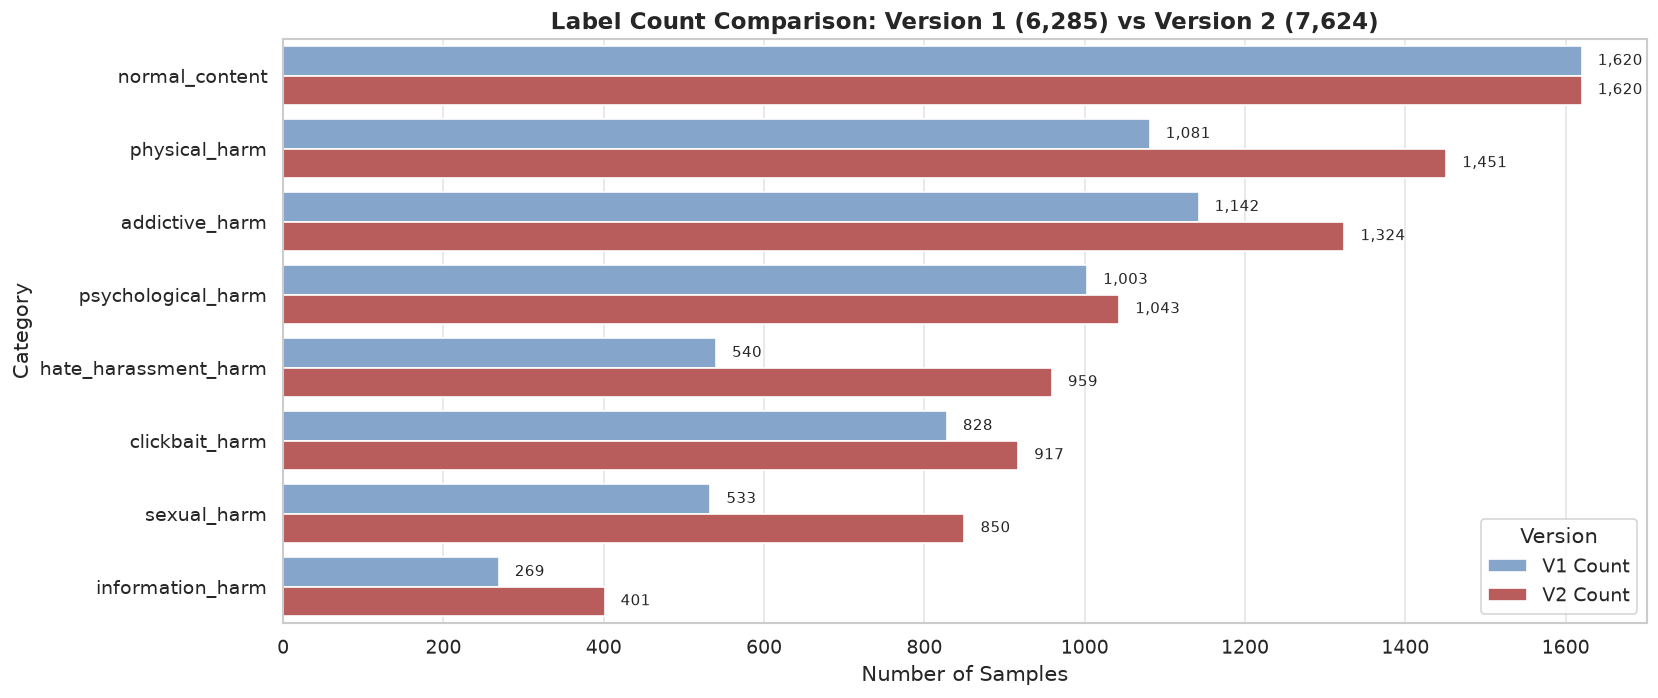

Saved comparison figure: D:\Workspace\hierachical-multimodel-multilabel\images\eda\v2\label_distribution_v1_vs_v2.png


C:\Users\KietKlat\AppData\Local\Temp\ipykernel_29536\1387071043.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stats_df, x="Count", y="Category", palette=colors, ax=axes[0])
C:\Users\KietKlat\AppData\Local\Temp\ipykernel_29536\1387071043.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stats_df, x="Prevalence (%)", y="Category", palette=colors, ax=axes[1])


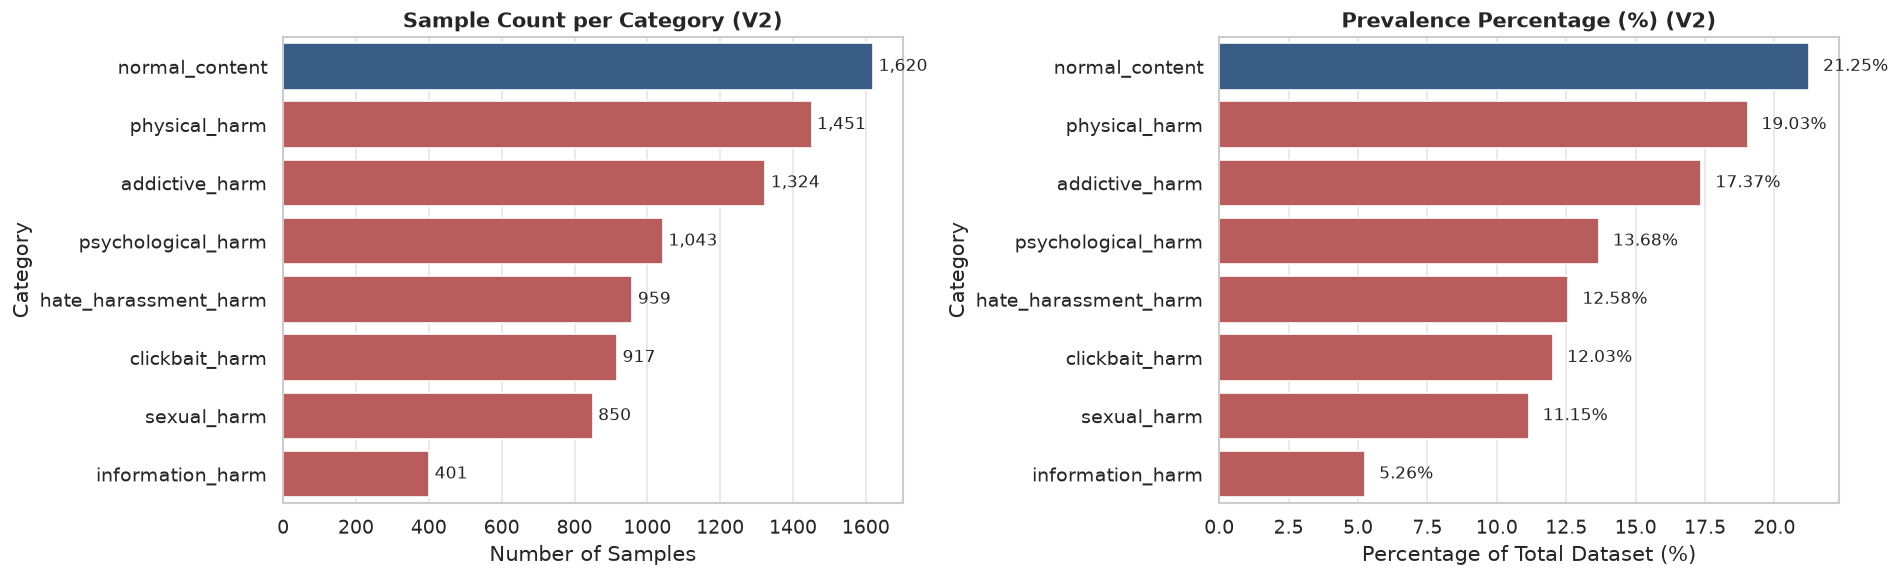

Saved figure: D:\Workspace\hierachical-multimodel-multilabel\images\eda\v2\label_distribution_v2.png


In [14]:
n_total = len(df_labels)
all_eval_cols = ["normal_content"] + harm_cols
counts = df_labels[all_eval_cols].sum()
prevalences = (counts / n_total) * 100

stats_df = pd.DataFrame({
    "Category": all_eval_cols,
    "Count": counts.values,
    "Prevalence (%)": prevalences.values.round(2)
}).sort_values(by="Count", ascending=False).reset_index(drop=True)

print(f"=== {DATASET_VERSION.upper()} LABEL DISTRIBUTION (Total: {n_total:,} samples) ===")
display(stats_df)

# If v2, also compute and display comparison table with v1
if DATASET_VERSION == "v2":
    v1_counts = df_v1[all_eval_cols].sum()
    v1_pct = (v1_counts / len(df_v1) * 100).round(2)
    comp_df = pd.DataFrame({
        "Category": all_eval_cols,
        "V1 Count": v1_counts.values,
        "V1 (%)": v1_pct.values,
        "V2 Count": counts.values,
        "V2 (%)": prevalences.values.round(2),
        "Delta Count": (counts - v1_counts).values,
        "Delta (%)": (prevalences - v1_pct).round(2).values
    }).sort_values(by="V2 Count", ascending=False).reset_index(drop=True)
    
    print("\n=== COMPARISON: VERSION 1 vs VERSION 2 ===")
    display(comp_df)
    
    # Plot comparative chart
    fig, ax = plt.subplots(figsize=(14, 6))
    melted_comp = comp_df.melt(id_vars=["Category"], value_vars=["V1 Count", "V2 Count"], var_name="Version", value_name="Count")
    sns.barplot(data=melted_comp, y="Category", x="Count", hue="Version", palette=["#7ba4d5", "#c94c4c"], ax=ax)
    ax.set_title("Label Count Comparison: Version 1 (6,285) vs Version 2 (7,624)", fontweight="bold", fontsize=14)
    ax.set_xlabel("Number of Samples")
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(f"{int(width):,}", (width + 20, p.get_y() + p.get_height() / 2.), va="center", fontsize=9)
    plt.tight_layout()
    comp_fig_path = figures_dir / "label_distribution_v1_vs_v2.png"
    plt.savefig(comp_fig_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved comparison figure: {comp_fig_path}")

# Standard distribution plot for active version
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors = ["#2b5c8f" if cat == "normal_content" else "#c94c4c" for cat in stats_df["Category"]]

sns.barplot(data=stats_df, x="Count", y="Category", palette=colors, ax=axes[0])
axes[0].set_title(f"Sample Count per Category ({DATASET_VERSION.upper()})", fontweight="bold")
axes[0].set_xlabel("Number of Samples")
for i, count in enumerate(stats_df["Count"]):
    axes[0].text(count + 15, i, f"{count:,}", va="center", fontsize=10)

sns.barplot(data=stats_df, x="Prevalence (%)", y="Category", palette=colors, ax=axes[1])
axes[1].set_title(f"Prevalence Percentage (%) ({DATASET_VERSION.upper()})", fontweight="bold")
axes[1].set_xlabel("Percentage of Total Dataset (%)")
for i, prev in enumerate(stats_df["Prevalence (%)"]):
    axes[1].text(prev + 0.5, i, f"{prev:.2f}%", va="center", fontsize=10)

plt.tight_layout()
fig_path = figures_dir / f"label_distribution_{DATASET_VERSION}.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig_path}")


## 3. Multi-label Cardinality and Label Combinations

We inspect the distribution of harm labels assigned per sample to quantify single-label vs multi-label complexity.


,Num Harms,Count,Percentage (%)
0,0,1620,21.25
1,1,5066,66.45
2,2,935,12.26
3,3,3,0.04


C:\Users\KietKlat\AppData\Local\Temp\ipykernel_29536\3270108149.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cardinality_df, x="Num Harms", y="Count", palette="Blues_d", ax=ax)


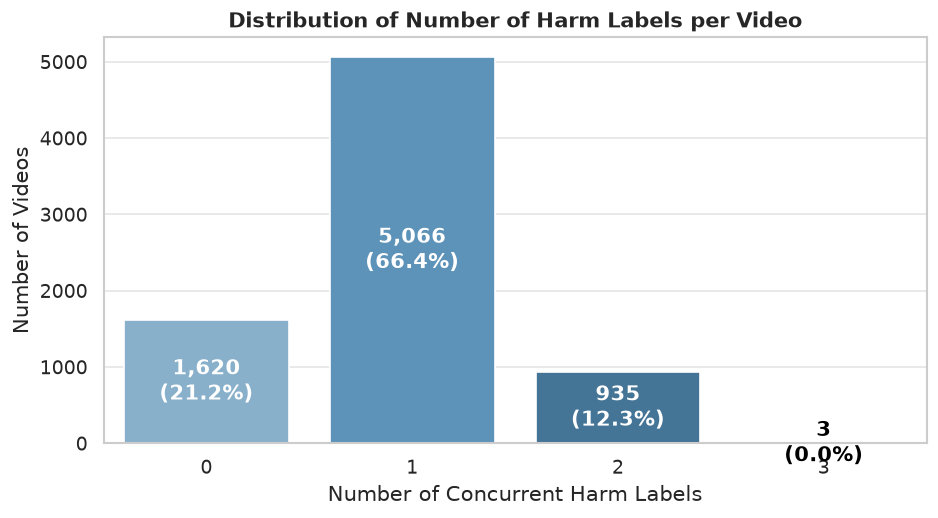

Saved figure: D:\Workspace\hierachical-multimodel-multilabel\images\eda\v2\label_cardinality.png
Top 15 Label Combinations in Dataset:


,Combination,Count
0,normal_content,1620
1,physical_harm,991
2,psychological_harm,924
3,clickbait_harm,795
4,addictive_harm,749
5,sexual_harm,748
6,hate_harassment_harm,488
7,information_harm,371
8,addictive_harm + physical_harm,262
9,hate_harassment_harm + addictive_harm,253


In [15]:
cardinality_counts = df_labels["total_harms"].value_counts().sort_index()
cardinality_pct = (cardinality_counts / n_total * 100).round(2)

cardinality_df = pd.DataFrame({
    "Num Harms": cardinality_counts.index,
    "Count": cardinality_counts.values,
    "Percentage (%)": cardinality_pct.values
})
display(cardinality_df)

# Visualize label cardinality
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=cardinality_df, x="Num Harms", y="Count", palette="Blues_d", ax=ax)
ax.set_title("Distribution of Number of Harm Labels per Video", fontweight="bold")
ax.set_xlabel("Number of Concurrent Harm Labels")
ax.set_ylabel("Number of Videos")
for p in ax.patches:
    val = int(p.get_height())
    pct = (val / n_total) * 100
    ax.annotate(f"{val:,}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha="center", va="center", color="white" if val > 500 else "black", fontweight="bold")

plt.tight_layout()
fig_path = figures_dir / "label_cardinality.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig_path}")

# Examine top multi-label combinations
def get_combination(row):
    active = [c for c in harm_cols if row[c] == 1]
    return " + ".join(active) if active else "normal_content"

df_labels["label_combination"] = df_labels.apply(get_combination, axis=1)
combo_counts = df_labels["label_combination"].value_counts().head(15)

print("Top 15 Label Combinations in Dataset:")
combo_df = pd.DataFrame({"Combination": combo_counts.index, "Count": combo_counts.values})
display(combo_df)


## 4. Label Co-occurrence Analysis

We compute the pairwise co-occurrence matrix among the 7 harm categories on videos with at least one harm.


,information_harm,sexual_harm,psychological_harm,hate_harassment_harm,clickbait_harm,addictive_harm,physical_harm
information_harm,401,4,0,21,1,1,3
sexual_harm,4,850,4,17,31,17,30
psychological_harm,0,4,1043,19,24,32,43
hate_harassment_harm,21,17,19,959,47,253,114
clickbait_harm,1,31,24,47,917,11,8
addictive_harm,1,17,32,253,11,1324,264
physical_harm,3,30,43,114,8,264,1451


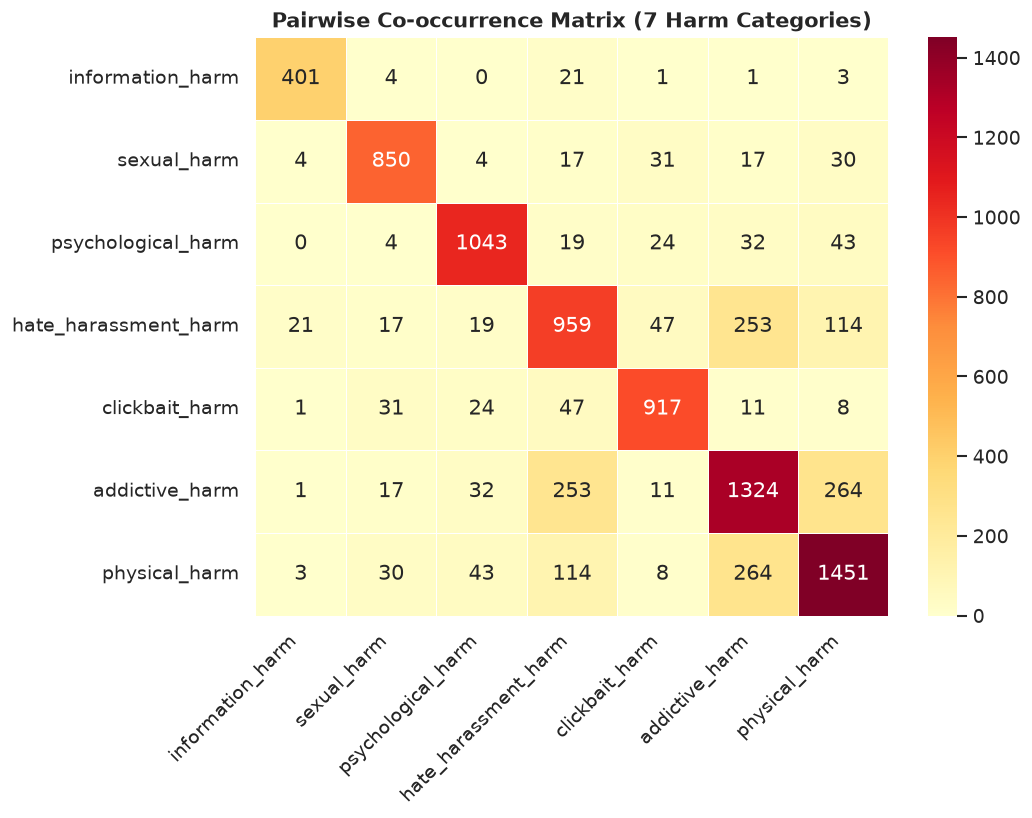

Saved figure: D:\Workspace\hierachical-multimodel-multilabel\images\eda\v2\label_cooccurrence_matrix.png


In [16]:
harm_sub = df_labels[harm_cols]
co_occurrence = harm_sub.T.dot(harm_sub)

# Display raw co-occurrence counts
display(co_occurrence)

# Plot co-occurrence heatmap
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(co_occurrence, annot=True, fmt="d", cmap="YlOrRd", cbar=True, ax=ax, linewidths=0.5)
ax.set_title("Pairwise Co-occurrence Matrix (7 Harm Categories)", fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
fig_path = figures_dir / "label_cooccurrence_matrix.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig_path}")


## 5. Video Technical Metadata Extraction and Caching

Extracts technical attributes from each video file:
- `duration_sec`: Duration in seconds
- `width`, `height`: Pixel dimensions
- `aspect_ratio`: Classified ratio (9:16 vertical, 16:9 horizontal, 1:1, or custom)
- `fps`: Frame rate
- `frame_count`: Total number of frames
- `file_size_mb`: File size on disk in megabytes
- `is_valid`: Boolean flag checking whether OpenCV can read the file

Extraction is parallelized via `ThreadPoolExecutor` and cached to `data/video_metadata.csv`.


In [17]:
def extract_video_metadata(filepath):
    """Extract technical properties of a video using OpenCV."""
    path = Path(filepath)
    filename = path.name
    try:
        size_mb = round(os.path.getsize(path) / (1024 * 1024), 2)
    except Exception:
        size_mb = 0.0

    # Safely compute relative path
    try:
        rel_video_path = str(path.relative_to(repo_root / "data"))
    except ValueError:
        rel_video_path = str(path)

    part_name = path.parent.name

    try:
        cap = cv2.VideoCapture(str(path))
        if not cap.isOpened():
            return {
                "filename": filename,
                "video_path": rel_video_path,
                "part": part_name,
                "duration_sec": 0.0,
                "width": 0,
                "height": 0,
                "aspect_ratio": "unknown",
                "fps": 0.0,
                "frame_count": 0,
                "file_size_mb": size_mb,
                "is_valid": False,
                "error": "Failed to open video container"
            }

        fps = cap.get(cv2.CAP_PROP_FPS) or 0.0
        frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0.0
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH) or 0)
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT) or 0)
        cap.release()

        duration = round(frame_count / fps, 2) if (fps > 0 and frame_count > 0) else 0.0

        ar_label = f"{width}:{height}"
        if width > 0 and height > 0:
            ratio = width / height
            if abs(ratio - 9/16) < 0.05:
                ar_label = "9:16 (Vertical)"
            elif abs(ratio - 16/9) < 0.05:
                ar_label = "16:9 (Horizontal)"
            elif abs(ratio - 1.0) < 0.05:
                ar_label = "1:1 (Square)"
            else:
                ar_label = f"{width}x{height} (Other)"

        return {
            "filename": filename,
            "video_path": rel_video_path,
            "part": part_name,
            "duration_sec": duration,
            "width": width,
            "height": height,
            "aspect_ratio": ar_label,
            "fps": round(fps, 2),
            "frame_count": int(frame_count),
            "file_size_mb": size_mb,
            "is_valid": True,
            "error": ""
        }
    except Exception as e:
        return {
            "filename": filename,
            "video_path": rel_video_path,
            "part": part_name,
            "duration_sec": 0.0,
            "width": 0,
            "height": 0,
            "aspect_ratio": "unknown",
            "fps": 0.0,
            "frame_count": 0,
            "file_size_mb": size_mb,
            "is_valid": False,
            "error": str(e)
        }

# Incremental metadata loading / extraction
if metadata_cache_path.exists():
    print(f"Loading cached video metadata from: {metadata_cache_path}")
    df_meta = pd.read_csv(metadata_cache_path)
else:
    # If v2, reuse v1 cache (6,285 items) and incrementally extract only the new 1,351 items
    v1_cache_path = repo_root / "data" / "video_metadata.csv"
    existing_meta_records = []
    already_scanned_filenames = set()

    if v1_cache_path.exists():
        print(f"Found base v1 metadata cache ({v1_cache_path.name}), loading {v1_cache_path}...")
        df_base_meta = pd.read_csv(v1_cache_path)
        existing_meta_records = df_base_meta.to_dict("records")
        already_scanned_filenames = set(df_base_meta["filename"].astype(str))
        print(f"Loaded {len(already_scanned_filenames):,} records from v1 cache.")

    # Find videos that need OpenCV extraction
    unscanned_video_files = [path for fname, path in existing_video_paths.items() if fname not in already_scanned_filenames]
    
    if unscanned_video_files:
        print(f"Extracting OpenCV metadata for {len(unscanned_video_files):,} new/unscanned video files...")
        start_t = time.time()
        with ThreadPoolExecutor(max_workers=8) as executor:
            new_meta_records = list(executor.map(extract_video_metadata, unscanned_video_files))
        print(f"Extraction completed in {time.time() - start_t:.2f}s")
        all_records = existing_meta_records + new_meta_records
    else:
        print("All video files already have cached metadata.")
        all_records = existing_meta_records

    df_meta = pd.DataFrame(all_records)
    df_meta.to_csv(metadata_cache_path, index=False)
    print(f"Saved complete metadata to: {metadata_cache_path}")

print(f"Total metadata rows: {len(df_meta):,}")
display(df_meta.head())


Loading cached video metadata from: D:\Workspace\hierachical-multimodel-multilabel\data\video_metadata_v2.csv
Total metadata rows: 7,636


,filename,video_path,part,duration_sec,width,height,aspect_ratio,fps,frame_count,file_size_mb,is_valid,error
0,00030e61-7543965137888103711.mp4,video_parts\part_01\00030e61-75439651378881037...,part_01,11.67,720,1280,9:16 (Vertical),30.0,350,0.46,True,NaN
1,0008f27d-7571807250499652884.mp4,video_parts\part_01\0008f27d-75718072504996528...,part_01,21.20,720,1280,9:16 (Vertical),30.0,636,1.98,True,NaN
2,0018559b-7536954002601184519.mp4,video_parts\part_01\0018559b-75369540026011845...,part_01,24.80,1080,1920,9:16 (Vertical),30.0,744,0.94,True,NaN
3,001bbcb4-dangket1982-2025-04-17_1931-nhung-cuo...,video_parts\part_01\001bbcb4-dangket1982-2025-...,part_01,62.73,576,1024,9:16 (Vertical),30.0,1882,19.88,True,NaN
4,002362a3-7539053216764333330.mp4,video_parts\part_01\002362a3-75390532167643333...,part_01,27.53,1104,720,1104:720,30.0,826,1.34,True,NaN


## 6. Video Duration Distribution and Summary

Analysis of video durations in seconds, including standard percentiles (25%, 50%, 75%, 90%, 95%, 99%).


,Duration (s)
count,7636.000000
mean,47.814248
std,50.063636
min,1.040000
25%,17.637500
50%,30.460000
75%,60.530000
90%,100.165000
95%,142.320000
99%,248.819500


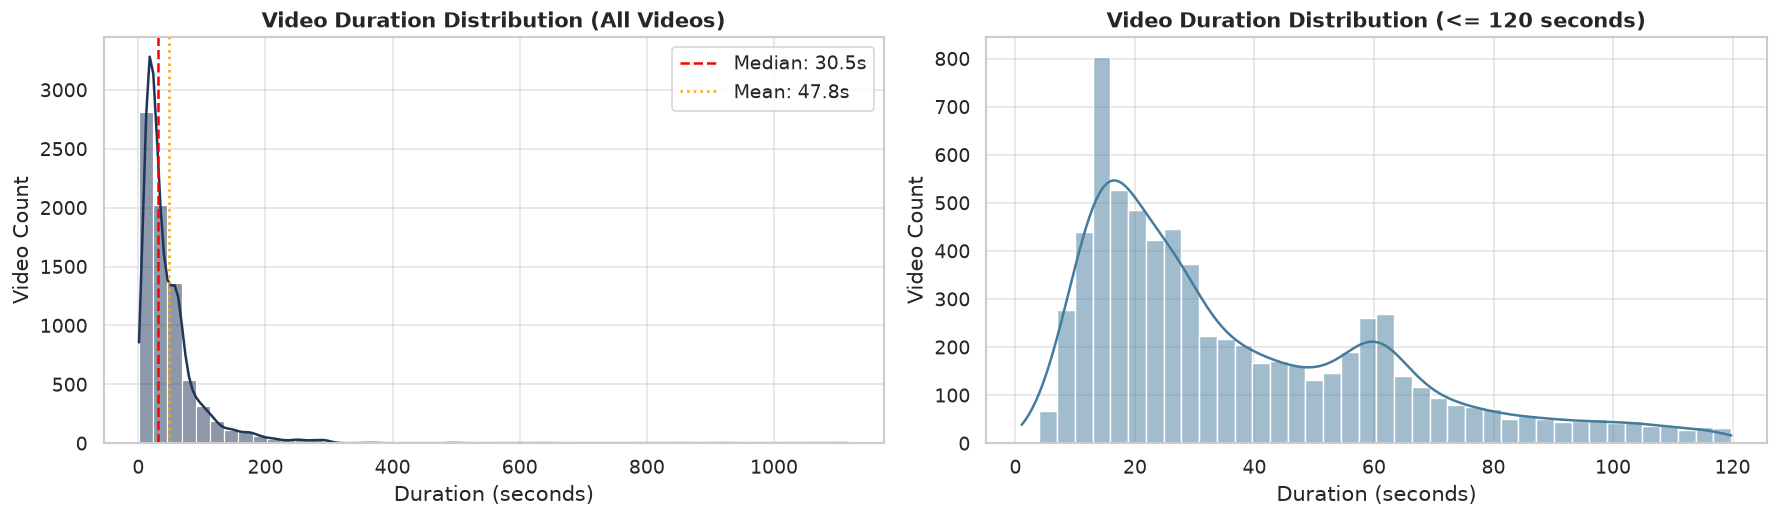

Saved figure: D:\Workspace\hierachical-multimodel-multilabel\images\eda\v2\video_duration_distribution.png


In [18]:
valid_meta = df_meta[df_meta["is_valid"] & (df_meta["duration_sec"] > 0)]
duration_series = valid_meta["duration_sec"]

desc = duration_series.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame("Duration (s)")
display(desc)

# Visualize duration distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Full histogram with KDE
sns.histplot(duration_series, bins=50, kde=True, color="#1d3557", ax=axes[0])
axes[0].set_title("Video Duration Distribution (All Videos)", fontweight="bold")
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Video Count")
axes[0].axvline(duration_series.median(), color="red", linestyle="--", label=f"Median: {duration_series.median():.1f}s")
axes[0].axvline(duration_series.mean(), color="orange", linestyle=":", label=f"Mean: {duration_series.mean():.1f}s")
axes[0].legend()

# Zoom-in on typical short-form range (<= 120s)
sns.histplot(duration_series[duration_series <= 120], bins=40, kde=True, color="#457b9d", ax=axes[1])
axes[1].set_title("Video Duration Distribution (<= 120 seconds)", fontweight="bold")
axes[1].set_xlabel("Duration (seconds)")
axes[1].set_ylabel("Video Count")

plt.tight_layout()
fig_path = figures_dir / "video_duration_distribution.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig_path}")


## 7. Resolution and Aspect Ratio Distribution

TikTok and short-form video models are typically optimized for vertical 9:16 content. We inspect frame resolutions and orientations.


,Aspect Ratio,Count,Percentage (%)
0,9:16 (Vertical),6100,79.88
1,16:9 (Horizontal),340,4.45
2,1:1 (Square),273,3.58
3,576:768,76,1.00
4,1252x576 (Other),70,0.92
...,...,...,...
323,800x360 (Other),1,0.01
324,576x870 (Other),1,0.01
325,360x800 (Other),1,0.01
326,1246x576 (Other),1,0.01


C:\Users\KietKlat\AppData\Local\Temp\ipykernel_29536\228400130.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ar_counts, x="Count", y="Aspect Ratio", palette="mako", ax=axes[0])
C:\Users\KietKlat\AppData\Local\Temp\ipykernel_29536\228400130.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_res, x="Count", y="Resolution", palette="viridis", ax=axes[1])


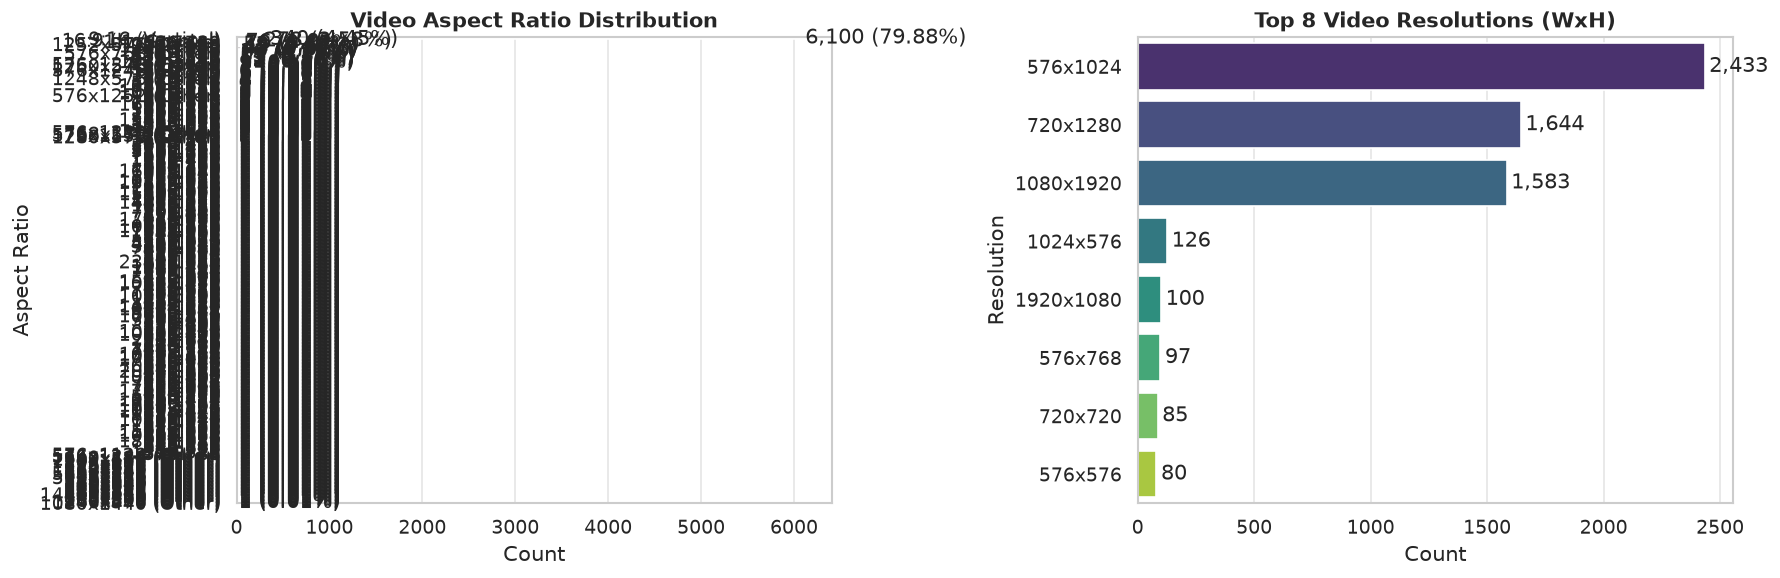

Saved figure: D:\Workspace\hierachical-multimodel-multilabel\images\eda\v2\video_resolution_distribution.png


In [19]:
ar_counts = valid_meta["aspect_ratio"].value_counts().reset_index()
ar_counts.columns = ["Aspect Ratio", "Count"]
ar_counts["Percentage (%)"] = (ar_counts["Count"] / len(valid_meta) * 100).round(2)
display(ar_counts)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Aspect ratio bar chart
sns.barplot(data=ar_counts, x="Count", y="Aspect Ratio", palette="mako", ax=axes[0])
axes[0].set_title("Video Aspect Ratio Distribution", fontweight="bold")
for i, count in enumerate(ar_counts["Count"]):
    axes[0].text(count + 20, i, f"{count:,} ({ar_counts['Percentage (%)'].iloc[i]}%)", va="center")

# Top exact resolutions
valid_meta["resolution_str"] = valid_meta["width"].astype(str) + "x" + valid_meta["height"].astype(str)
top_res = valid_meta["resolution_str"].value_counts().head(8).reset_index()
top_res.columns = ["Resolution", "Count"]
sns.barplot(data=top_res, x="Count", y="Resolution", palette="viridis", ax=axes[1])
axes[1].set_title("Top 8 Video Resolutions (WxH)", fontweight="bold")
for i, count in enumerate(top_res["Count"]):
    axes[1].text(count + 20, i, f"{count:,}", va="center")

plt.tight_layout()
fig_path = figures_dir / "video_resolution_distribution.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig_path}")


## 8. Frame Rate (FPS) and File Size Distribution

Examines video file sizes on disk (in MB) and framerate characteristics.


C:\Users\KietKlat\AppData\Local\Temp\ipykernel_29536\4101520730.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_fps, x="FPS", y="Count", palette="rocket", ax=axes[1])


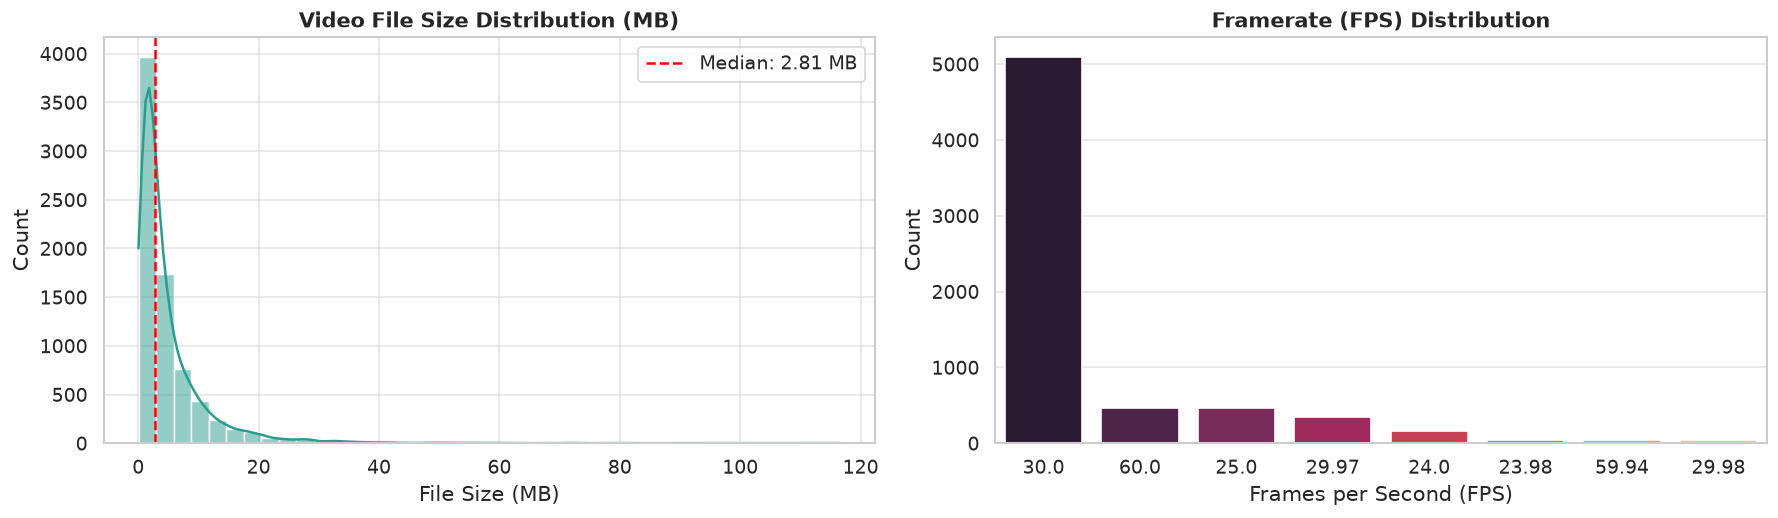

Saved figure: D:\Workspace\hierachical-multimodel-multilabel\images\eda\v2\video_file_size_distribution.png


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# File size distribution
sns.histplot(valid_meta["file_size_mb"], bins=40, color="#2a9d8f", kde=True, ax=axes[0])
axes[0].set_title("Video File Size Distribution (MB)", fontweight="bold")
axes[0].set_xlabel("File Size (MB)")
axes[0].set_ylabel("Count")
axes[0].axvline(valid_meta["file_size_mb"].median(), color="red", linestyle="--",
                label=f"Median: {valid_meta['file_size_mb'].median():.2f} MB")
axes[0].legend()

# FPS distribution
top_fps = valid_meta["fps"].value_counts().head(8).reset_index()
top_fps.columns = ["FPS", "Count"]
top_fps["FPS"] = top_fps["FPS"].astype(str)
sns.barplot(data=top_fps, x="FPS", y="Count", palette="rocket", ax=axes[1])
axes[1].set_title("Framerate (FPS) Distribution", fontweight="bold")
axes[1].set_xlabel("Frames per Second (FPS)")
axes[1].set_ylabel("Count")

plt.tight_layout()
fig_path = figures_dir / "video_file_size_distribution.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig_path}")


## 9. Integrity Check and Outlier Reporting

We flag potential anomalies for dataset audit without modifying or deleting files on disk:
1. **Unreadable / Corrupt Videos**: Files where `is_valid == False` or `duration_sec <= 0`.
2. **Long Videos**: Videos exceeding standard short-form thresholds (> 180 seconds or > 300 seconds).

Flagged outliers are exported to `data/video_outliers_report.csv`.


In [21]:
# Report path configured in Cell 1 for active version
print(f"Outliers report destination: {outliers_report_path}")

# Unreadable videos
unreadable = df_meta[~df_meta["is_valid"]].copy()
unreadable["outlier_reason"] = "Corrupt or unreadable container: " + unreadable["error"].astype(str)

# Extreme duration outliers (< 2 seconds or > 180 seconds)
extreme_dur = df_meta[df_meta["is_valid"] & ((df_meta["duration_sec"] < 2.0) | (df_meta["duration_sec"] > 180.0))].copy()
extreme_dur["outlier_reason"] = "Extreme duration (" + extreme_dur["duration_sec"].astype(str) + "s)"

# Non-standard framerates (< 10 fps or > 65 fps)
extreme_fps = df_meta[df_meta["is_valid"] & ((df_meta["fps"] < 10.0) | (df_meta["fps"] > 65.0))].copy()
extreme_fps["outlier_reason"] = "Extreme framerate (" + extreme_fps["fps"].astype(str) + " fps)"

outliers_df = pd.concat([unreadable, extreme_dur, extreme_fps], ignore_index=True)
outliers_df.to_csv(outliers_report_path, index=False)
print(f"Total flagged outliers ({DATASET_VERSION.upper()}): {len(outliers_df)} samples")
print(f"Saved outlier report: {outliers_report_path}")
if len(outliers_df) > 0:
    display(outliers_df[["filename", "part", "duration_sec", "aspect_ratio", "fps", "file_size_mb", "outlier_reason"]].head(15))
else:
    print("SUCCESS: Zero outliers found in active dataset.")


Outliers report destination: D:\Workspace\hierachical-multimodel-multilabel\data\video_outliers_report_v2.csv
Total flagged outliers (V2): 213 samples
Saved outlier report: D:\Workspace\hierachical-multimodel-multilabel\data\video_outliers_report_v2.csv


,filename,part,duration_sec,aspect_ratio,fps,file_size_mb,outlier_reason
0,05d629ba-7564648545840614663.mp4,part_01,207.61,9:16 (Vertical),29.75,25.39,Extreme duration (207.61s)
1,065a59b5-7518318354629725447.mp4,part_01,226.93,9:16 (Vertical),30.00,10.55,Extreme duration (226.93s)
2,097f1e26-7580446177963871506.mp4,part_01,252.53,9:16 (Vertical),30.00,13.14,Extreme duration (252.53s)
3,0d67e6d1-7571782099821219090.mp4,part_01,212.80,9:16 (Vertical),30.00,6.83,Extreme duration (212.8s)
4,0fdf8bdb-7572888703165533460.mp4,part_01,185.63,9:16 (Vertical),29.96,13.75,Extreme duration (185.63s)
5,122497d0-7585865931029482768.mp4,part_01,214.87,9:16 (Vertical),30.00,11.69,Extreme duration (214.87s)
6,12f19823-viet.nam.anh.hung-2023-02-26_1721-Tha...,part_01,258.32,9:16 (Vertical),25.00,10.29,Extreme duration (258.32s)
7,13766f7e-7565919090183916808.mp4,part_01,269.97,9:16 (Vertical),30.00,36.84,Extreme duration (269.97s)
8,16bcc7d9-7604888654040976661.mp4,part_01,266.17,16:9 (Horizontal),29.79,18.19,Extreme duration (266.17s)
9,172d7350-7557018103884811527.mp4,part_01,244.42,9:16 (Vertical),23.99,22.46,Extreme duration (244.42s)
